# 分類タスクの評価尺度と閾値調整（Fβ・特異度・不均衡データ）

書籍 第1章「自然言語処理システムのデザイン」（1-4 評価：評価尺度とエラー分析、練習問題 2 など）に対応する演習ノートブックです。
CPU のみ・数秒で実行でき、追加ライブラリのインストールは不要です。

1. **基本 4 尺度と特異度（Specificity）・偽陽性率（FPR）**（p.33〜35、脚注 31）
2. **重み付き調和平均 $F_\beta$（$F_{0.5}$ / $F_1$ / $F_2$）と閾値調整**（「再現率 9 割固定時の適合率」p.34〜35）
3. **不均衡データにおける「正解率の罠」**
4. **多クラス分類の Macro 平均と Micro 平均**

（※ 生成タスクの評価尺度 BLEU については、第 4 章の[統計的機械翻訳の基礎と BLEU 評価](https://colab.research.google.com/github/mamorlis/nlpbook/blob/main/notebooks/ch4_smt_bleu.ipynb)へ切り出しました。）

## 1. 準備

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    f1_score,
    fbeta_score,
    precision_score,
    recall_score,
)

---

## 2. 分類タスクの評価尺度と特異度（定義式の実装と検証）

2値分類（正例 `1` / 負例 `0`）の予測結果から混同行列の 4 要素（TP, FP, FN, TN）を数え、定義式どおりに計算します。

- **正解率（Accuracy）**: $\displaystyle \frac{TP + TN}{TP + FP + FN + TN}$
- **適合率（Precision）**: $\displaystyle \frac{TP}{TP + FP}$（正例と予測したうち実際に正例だった割合）
- **再現率（Recall）**: $\displaystyle \frac{TP}{TP + FN}$（実際の正例のうち正しく検出できた割合）
- **特異度（Specificity）**: $\displaystyle \frac{TN}{TN + FP}$（実際の負例のうち正しく負例と予測できた割合。脚注 31）
- **偽陽性率（FPR）**: $\displaystyle \frac{FP}{TN + FP} = 1 - \text{Specificity}$
- **$F_\beta$ スコア**: $\displaystyle (1 + \beta^2) \frac{\text{Precision} \cdot \text{Recall}}{(\beta^2 \cdot \text{Precision}) + \text{Recall}}$（$\beta=1$ が $F_1$、$\beta=0.5$ は適合率重視、$\beta=2$ は再現率重視）

In [2]:
def compute_binary_metrics(y_true, y_pred, beta=1.0):
    """混同行列から各種評価尺度を定義式どおりに計算する"""
    tp = sum(t == 1 and p == 1 for t, p in zip(y_true, y_pred))
    fp = sum(t == 0 and p == 1 for t, p in zip(y_true, y_pred))
    fn = sum(t == 1 and p == 0 for t, p in zip(y_true, y_pred))
    tn = sum(t == 0 and p == 0 for t, p in zip(y_true, y_pred))

    acc = (tp + tn) / (tp + fp + fn + tn)
    prec = tp / (tp + fp) if (tp + fp) > 0 else 0.0
    rec = tp / (tp + fn) if (tp + fn) > 0 else 0.0
    spec = tn / (tn + fp) if (tn + fp) > 0 else 0.0
    fpr = 1.0 - spec
    denom = (beta ** 2) * prec + rec
    fbeta = (1 + beta ** 2) * prec * rec / denom if denom > 0 else 0.0
    return {
        "TP": tp, "FP": fp, "FN": fn, "TN": tn,
        "accuracy": acc, "precision": prec, "recall": rec,
        "specificity": spec, "fpr": fpr, "fbeta": fbeta,
    }

y_true = [1, 1, 1, 1, 1, 0, 0, 0, 0, 0]
y_pred = [1, 1, 1, 0, 0, 1, 0, 0, 0, 0]

m1 = compute_binary_metrics(y_true, y_pred, beta=1.0)
m05 = compute_binary_metrics(y_true, y_pred, beta=0.5)
print(f"TP={m1['TP']}, FP={m1['FP']}, FN={m1['FN']}, TN={m1['TN']}")
print(
    f"手計算  : Acc={m1['accuracy']:.4f}, Prec={m1['precision']:.4f}, "
    f"Rec={m1['recall']:.4f}, Spec={m1['specificity']:.4f}, "
    f"F1={m1['fbeta']:.4f}, F0.5={m05['fbeta']:.4f}"
)
print(
    f"sklearn : Acc={accuracy_score(y_true, y_pred):.4f}, Prec={precision_score(y_true, y_pred):.4f}, "
    f"Rec={recall_score(y_true, y_pred):.4f}, "
    f"F1={fbeta_score(y_true, y_pred, beta=1.0):.4f}, F0.5={fbeta_score(y_true, y_pred, beta=0.5):.4f}"
)

TP=3, FP=1, FN=2, TN=4
手計算  : Acc=0.7000, Prec=0.7500, Rec=0.6000, Spec=0.8000, F1=0.6667, F0.5=0.7143
sklearn : Acc=0.7000, Prec=0.7500, Rec=0.6000, F1=0.6667, F0.5=0.7143


---

## 3. $F_\beta$ スコアと閾値調整（p.34〜35）

書籍 1-4-1（p.34〜35）では、アプリケーションの性質によって「適合率と再現率のどちらを重視するか」が変わることが解説されています。

- **誤検出を嫌う用途**（文法誤り訂正や一般ユーザ向け検索の上位表示）：**適合率重視（$F_{0.5}$）**
- **漏れを許せない用途**（特許検索で後段の専門家がチェックする前提）：**再現率重視（$F_2$、または「再現率が 9 割になる閾値での適合率」）**

モデルの予測確率に対して判定閾値を動かしたとき、Precision / Recall / Specificity / $F_{0.5}$ / $F_1$ / $F_2$ がどうトレードオフになるか確認してみましょう。

,閾値,Precision,Recall,Specificity,F0.5 (適合率重視),F1,F2 (再現率重視)
0,0.15,0.252,1.000,0.256,0.296,0.402,0.627
1,0.20,0.284,1.000,0.369,0.331,0.442,0.664
2,0.25,0.342,1.000,0.519,0.394,0.510,0.722
3,0.30,0.400,1.000,0.625,0.455,0.571,0.769
4,0.35,0.465,1.000,0.712,0.521,0.635,0.813
5,0.40,0.541,1.000,0.788,0.595,0.702,0.855
6,0.45,0.635,1.000,0.856,0.685,0.777,0.897
7,0.50,0.698,0.925,0.900,0.734,0.796,0.869
8,0.55,0.818,0.900,0.950,0.833,0.857,0.882
9,0.60,0.865,0.800,0.969,0.851,0.831,0.812


再現率>=0.90 で適合率最大の閾値: 0.55 (Recall=0.9, Precision=0.818)
F0.5 最大の閾値                : 0.7 (Recall=0.625, Precision=0.962)


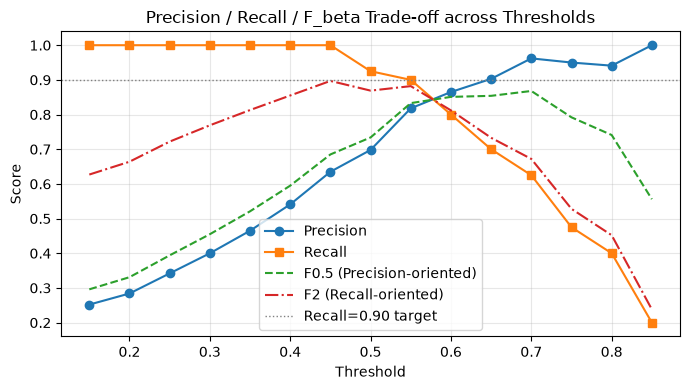

In [3]:
rng = np.random.default_rng(42)
n_pos, n_neg = 40, 160
y_scores = np.concatenate([rng.beta(4.5, 2.0, n_pos), rng.beta(1.8, 5.0, n_neg)])
y_labels = np.array([1] * n_pos + [0] * n_neg)

thresholds = np.round(np.linspace(0.15, 0.85, 15), 2)
records = []
for th in thresholds:
    pred = (y_scores >= th).astype(int)
    m1 = compute_binary_metrics(y_labels, pred, beta=1.0)
    m05 = compute_binary_metrics(y_labels, pred, beta=0.5)
    m2 = compute_binary_metrics(y_labels, pred, beta=2.0)
    records.append({
        "閾値": th,
        "Precision": round(m1["precision"], 3),
        "Recall": round(m1["recall"], 3),
        "Specificity": round(m1["specificity"], 3),
        "F0.5 (適合率重視)": round(m05["fbeta"], 3),
        "F1": round(m1["fbeta"], 3),
        "F2 (再現率重視)": round(m2["fbeta"], 3),
    })

df_th = pd.DataFrame(records)
display(df_th)

# 再現率 >= 0.90 を満たす範囲で最も適合率が高い閾値
rec90 = df_th[df_th["Recall"] >= 0.90]
best_rec90 = rec90.sort_values("Precision", ascending=False).iloc[0]
best_f05 = df_th.loc[df_th["F0.5 (適合率重視)"].idxmax()]
print(f"再現率>=0.90 で適合率最大の閾値: {best_rec90['閾値']} (Recall={best_rec90['Recall']}, Precision={best_rec90['Precision']})")
print(f"F0.5 最大の閾値                : {best_f05['閾値']} (Recall={best_f05['Recall']}, Precision={best_f05['Precision']})")

fig, ax = plt.subplots(figsize=(7, 4))
ax.plot(df_th["閾値"], df_th["Precision"], marker="o", label="Precision")
ax.plot(df_th["閾値"], df_th["Recall"], marker="s", label="Recall")
ax.plot(df_th["閾値"], df_th["F0.5 (適合率重視)"], linestyle="--", label="F0.5 (Precision-oriented)")
ax.plot(df_th["閾値"], df_th["F2 (再現率重視)"], linestyle="-.", label="F2 (Recall-oriented)")
ax.axhline(0.90, color="gray", linestyle=":", linewidth=1, label="Recall=0.90 target")
ax.set_xlabel("Threshold")
ax.set_ylabel("Score")
ax.set_title("Precision / Recall / F_beta Trade-off across Thresholds")
ax.legend()
ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()

- 誤検出を避けたい（適合率重視）タスクでは、**$F_{0.5}$ が最大になる高めの閾値 `0.70`（`Precision=0.962, Recall=0.625`）** が選ばれます。
- 逆に特許検索のように見逃しを減らしたい場合は閾値を下げ、**再現率 0.90 以上で適合率最大となる閾値 `0.55`（`Recall=0.900, Precision=0.818`）** や $F_2$ 重視の設定を選びます。

---

## 4. 不均衡データにおける「正解率の罠」

実際の NLP タスク（スパム検出、有害表現検出、希少な誤りの検出など）では、クラスの比率が大きく偏っている（**不均衡データ**）ことがよくあります。

100件のうち **95件が負例（0）、5件だけが正例（1）** というデータで、以下の 2 つのモデルを比較してみましょう。
- **モデル A（ダミー分類器）**: 入力を見ずに、すべて `0`（負例）と予測する
- **モデル B（実用的な分類器）**: 正例 5件のうち 4件を検出し、誤検出（FP）が 3件だけある

In [4]:
y_imb = [1] * 5 + [0] * 95
pred_dummy = [0] * 100
pred_model = [1, 1, 1, 1, 0] + [1, 1, 1] + [0] * 92

rows = []
for name, pred in [("モデルA（すべて0と予測）", pred_dummy), ("モデルB（正例を検出）", pred_model)]:
    rows.append({
        "モデル": name,
        "Accuracy": round(accuracy_score(y_imb, pred), 3),
        "Precision (正例)": round(precision_score(y_imb, pred, zero_division=0), 3),
        "Recall (正例)": round(recall_score(y_imb, pred, zero_division=0), 3),
        "F1 (正例)": round(f1_score(y_imb, pred, zero_division=0), 3),
        "Macro-F1": round(f1_score(y_imb, pred, average="macro", zero_division=0), 3),
    })

pd.DataFrame(rows)

,モデル,Accuracy,Precision (正例),Recall (正例),F1 (正例),Macro-F1
0,モデルA（すべて0と予測）,0.95,0.000,0.0,0.000,0.487
1,モデルB（正例を検出）,0.96,0.571,0.8,0.667,0.823


モデル A は何も検出していないにもかかわらず **Accuracy が 0.950** と非常に高く見えますが、正例の F1 は **0.000**、Macro-F1 も **0.487** にとどまります。不均衡データでは Accuracy だけでなく、適合率・再現率・F1（または Macro-F1）をあわせて確認することが重要です。

---

## 5. 多クラス分類の Macro 平均と Micro 平均

3クラス分類（`pos` / `neu` / `neg`）では、クラスごとの F1 をどのように集約するかによって値が大きく変わります。

- **Macro 平均**: 各クラスの F1 を**クラス数で単純平均**する（データ数が少ないクラスも対等に扱う）
- **Micro 平均**: 全クラスの TP・FP・FN を**合算してから**計算する（各事例を対等に扱うため、単一ラベル多クラス分類では Accuracy と一致する）

In [5]:
labels = ["pos", "neu", "neg"]
y_mc_true = ["pos"] * 40 + ["neu"] * 10 + ["neg"] * 10
y_mc_pred = (
    ["pos"] * 38 + ["neu"] * 2 +
    ["neu"] * 3  + ["pos"] * 7 +
    ["neg"] * 4  + ["pos"] * 6
)

print("混同行列（行: 正解 / 列: 予測）:")
display(pd.DataFrame(confusion_matrix(y_mc_true, y_mc_pred, labels=labels), index=labels, columns=labels))
print(classification_report(y_mc_true, y_mc_pred, labels=labels, digits=4))
print(f"Accuracy = {accuracy_score(y_mc_true, y_mc_pred):.4f}")
print(f"Micro-F1 = {f1_score(y_mc_true, y_mc_pred, average='micro'):.4f}")
print(f"Macro-F1 = {f1_score(y_mc_true, y_mc_pred, average='macro'):.4f}")

混同行列（行: 正解 / 列: 予測）:


,pos,neu,neg
pos,38,2,0
neu,7,3,0
neg,6,0,4


              precision    recall  f1-score   support

         pos     0.7451    0.9500    0.8352        40
         neu     0.6000    0.3000    0.4000        10
         neg     1.0000    0.4000    0.5714        10

    accuracy                         0.7500        60
   macro avg     0.7817    0.5500    0.6022        60
weighted avg     0.7634    0.7500    0.7187        60

Accuracy = 0.7500
Micro-F1 = 0.7500
Macro-F1 = 0.6022
